# Oasis Infobyte Internship — Level 2, Task 04: Google Play Store Analysis

## Objective

The objective of this project is to analyze the Google Play Store
dataset to understand application categories, ratings, installations,
pricing strategies, and user reviews.

The project focuses on:
- Cleaning and preparing app data.
- Analyzing app categories and ratings.
- Exploring app installation trends.
- Comparing free and paid applications.
- Studying the relationship between ratings, reviews, and installs.
- Analyzing user review sentiment.
- Identifying patterns related to app popularity and user satisfaction.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

In [2]:
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from google.colab import files
uploaded = files.upload()

Saving googleplaystore_user_reviews.csv to googleplaystore_user_reviews.csv


In [4]:
from google.colab import files
uploaded = files.upload()

Saving googleplaystore.csv to googleplaystore.csv


In [5]:
# Load the Google Play Store apps dataset
apps = pd.read_csv("googleplaystore.csv")

# Load the Google Play Store user reviews dataset
reviews = pd.read_csv("googleplaystore_user_reviews.csv")

# Display the first 5 rows
print("Google Play Store Apps Dataset:")
display(apps.head())

print("Google Play Store User Reviews Dataset:")
display(reviews.head())

# Display dataset shapes
print("Apps Dataset Shape:", apps.shape)
print("Reviews Dataset Shape:", reviews.shape)

Google Play Store Apps Dataset:


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


Google Play Store User Reviews Dataset:


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


Apps Dataset Shape: (10841, 13)
Reviews Dataset Shape: (64295, 5)


In [6]:
print("APP DATASET")
print("=" * 50)
print("Shape:", apps.shape)
print("\nColumns:")
print(apps.columns.tolist())
print("\nData types:")
print(apps.dtypes)
print("\nInformation:")
apps.info()
print("\nSummary statistics:")
display(apps.describe(include="all"))

APP DATASET
Shape: (10841, 13)

Columns:
['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']

Data types:
App                object
Category           object
Rating            float64
Reviews            object
Size               object
Installs           object
Type               object
Price              object
Content Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
dtype: object

Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5  

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
count,10841,10841,9367.000000,10841,10841,10841,10840,10841,10840,10841,10841,10833,10838
unique,9660,34,NaN,6002,462,22,3,93,6,120,1378,2832,33
top,ROBLOX,FAMILY,NaN,0,Varies with device,"1,000,000+",Free,0,Everyone,Tools,"August 3, 2018",Varies with device,4.1 and up
freq,9,1972,NaN,596,1695,1579,10039,10040,8714,842,326,1459,2451
mean,NaN,NaN,4.193338,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,0.537431,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,4.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,4.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,4.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
print("USER REVIEWS DATASET")
print("=" * 50)
print("Shape:", reviews.shape)
print("\nColumns:")
print(reviews.columns.tolist())
print("\nMissing values:")
print(reviews.isnull().sum())
display(reviews.head())

USER REVIEWS DATASET
Shape: (64295, 5)

Columns:
['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']

Missing values:
App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


## Data Cleaning

We first check missing values and duplicate records in both datasets.

Missing values may affect calculations and visualizations. Duplicate
app records can distort category counts and other summary statistics,
so they must be inspected before deciding how to handle them.

In [8]:
print("Missing values in apps dataset:")
print(apps.isnull().sum())
print("\nDuplicate rows in apps dataset:")
print(apps.duplicated().sum())
print("\nMissing values in reviews dataset:")
print(reviews.isnull().sum())
print("\nDuplicate rows in reviews dataset:")
print(reviews.duplicated().sum())

Missing values in apps dataset:
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Duplicate rows in apps dataset:
483

Missing values in reviews dataset:
App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64

Duplicate rows in reviews dataset:
33616


In [9]:
# Remove exact duplicate rows
apps = apps.drop_duplicates().copy()
reviews = reviews.drop_duplicates().copy()

# Remove app records without a name
apps = apps.dropna(subset=["App"]).copy()

# Remove reviews without review text or sentiment
reviews = reviews.dropna(subset=["Translated_Review", "Sentiment"]).copy()
print("Apps shape after cleaning:", apps.shape)
print("Reviews shape after cleaning:", reviews.shape)
print("\nRemaining missing values in apps:")
print(apps.isnull().sum())

Apps shape after cleaning: (10358, 13)
Reviews shape after cleaning: (29692, 5)

Remaining missing values in apps:
App                  0
Category             0
Rating            1465
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64


###  Clean the Rating Column

Ratings should fall between 1 and 5. We convert the column to numeric
and treat values outside this range as invalid.

Missing ratings are retained as missing because filling them with
an average could create misleading results.

In [10]:
apps["Rating"] = pd.to_numeric(apps["Rating"],errors="coerce")
invalid_ratings = ~apps["Rating"].between(1, 5)
print("Invalid or missing ratings:", invalid_ratings.sum())
apps.loc[invalid_ratings, "Rating"] = np.nan

Invalid or missing ratings: 1466


###  Convert Reviews and Installs to Numeric Values

The `Reviews` column should be numeric.

The `Installs` column contains commas and plus signs, such as
`10,000+`. We remove these characters before conversion.

In [11]:
apps["Reviews"] = pd.to_numeric(apps["Reviews"],errors="coerce")
apps["Installs"] = pd.to_numeric(apps["Installs"].astype(str).str.replace(",", "", regex=False).str.replace("+", "", regex=False),errors="coerce")
print(apps[["Reviews", "Installs"]].dtypes)
display(apps[["App", "Reviews", "Installs"]].head())

Reviews     float64
Installs    float64
dtype: object


,App,Reviews,Installs
0,Photo Editor & Candy Camera & Grid & ScrapBook,159.0,10000.0
1,Coloring book moana,967.0,500000.0
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",87510.0,5000000.0
3,Sketch - Draw & Paint,215644.0,50000000.0
4,Pixel Draw - Number Art Coloring Book,967.0,100000.0


###  Convert App Prices to Numeric Values

The `Price` column may contain the dollar symbol. We remove it and
convert the remaining values into numbers.

This makes it possible to compare free and paid applications.

In [12]:
apps["Price"] = pd.to_numeric(apps["Price"].astype(str).str.replace("$", "", regex=False),errors="coerce")
print("Price column converted to numeric values.")
display(apps[["App", "Type", "Price"]].head())

Price column converted to numeric values.


,App,Type,Price
0,Photo Editor & Candy Camera & Grid & ScrapBook,Free,0.0
1,Coloring book moana,Free,0.0
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",Free,0.0
3,Sketch - Draw & Paint,Free,0.0
4,Pixel Draw - Number Art Coloring Book,Free,0.0


###  Convert App Size to Megabytes

The `Size` column may contain values such as `19M`, `512k`, or `Varies with device`.

We convert values expressed in megabytes or kilobytes into megabytes.
Values that cannot be interpreted are recorded as missing.

In [13]:
def convert_size(size):
    size = str(size).strip()

    if size in ["nan", "Varies with device", ""]:
        return np.nan

    try:
        if size.endswith("M"):
            return float(size[:-1])

        if size.endswith("k"):
            return float(size[:-1]) / 1024

    except ValueError:
        return np.nan

    return np.nan

apps["Size_MB"] = apps["Size"].apply(convert_size)
display(apps[["App", "Size", "Size_MB"]].head(10))

,App,Size,Size_MB
0,Photo Editor & Candy Camera & Grid & ScrapBook,19M,19.0
1,Coloring book moana,14M,14.0
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",8.7M,8.7
3,Sketch - Draw & Paint,25M,25.0
4,Pixel Draw - Number Art Coloring Book,2.8M,2.8
5,Paper flowers instructions,5.6M,5.6
6,Smoke Effect Photo Maker - Smoke Editor,19M,19.0
7,Infinite Painter,29M,29.0
8,Garden Coloring Book,33M,33.0
9,Kids Paint Free - Drawing Fun,3.1M,3.1


In [14]:
apps["Type"] = apps["Type"].astype("string").str.strip().str.title()
print(apps["Type"].value_counts(dropna=False))

Type
Free    9591
Paid     765
<NA>       1
0          1
Name: count, dtype: Int64


##  Exploratory Data Analysis

###  App Category Distribution

We examine the number of applications in each category.

This helps us identify categories with a large number of applications
and categories with fewer applications.

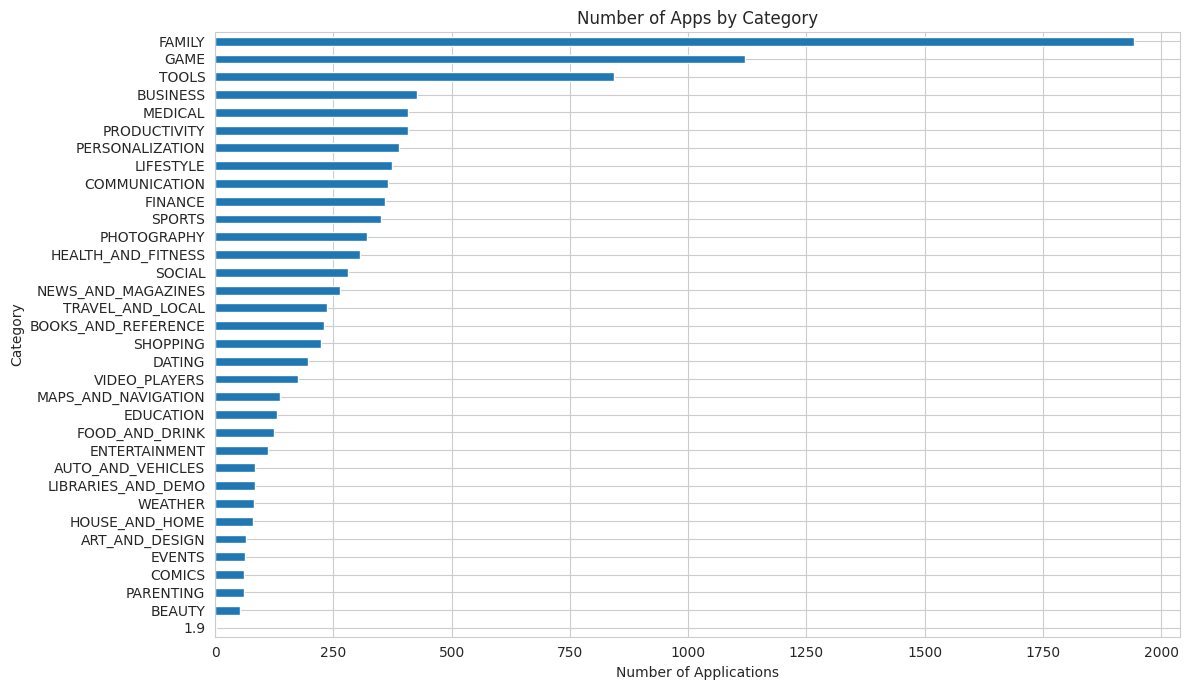

In [15]:
category_counts = apps["Category"].value_counts()
plt.figure(figsize=(12, 7))
category_counts.sort_values().plot(kind="barh")
plt.title("Number of Apps by Category")
plt.xlabel("Number of Applications")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

###  App Rating Distribution

We analyze app ratings to understand how applications are rated
by users. Only valid ratings between 1 and 5 are included.

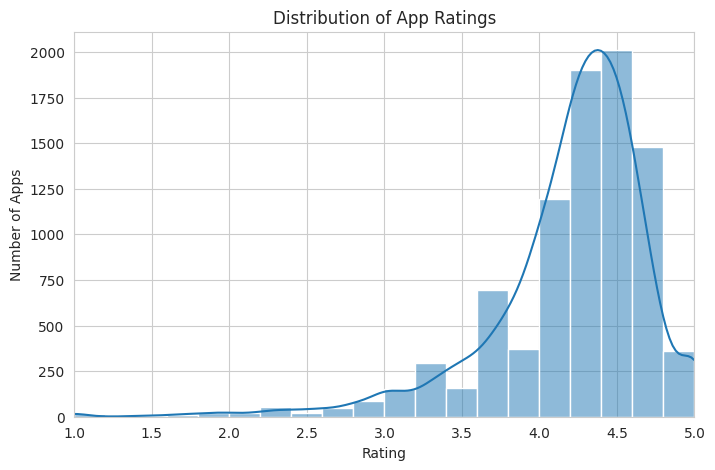

In [16]:
plt.figure(figsize=(8, 5))
sns.histplot(data=apps,x="Rating",bins=20,kde=True)
plt.title("Distribution of App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")
plt.xlim(1, 5)
plt.show()

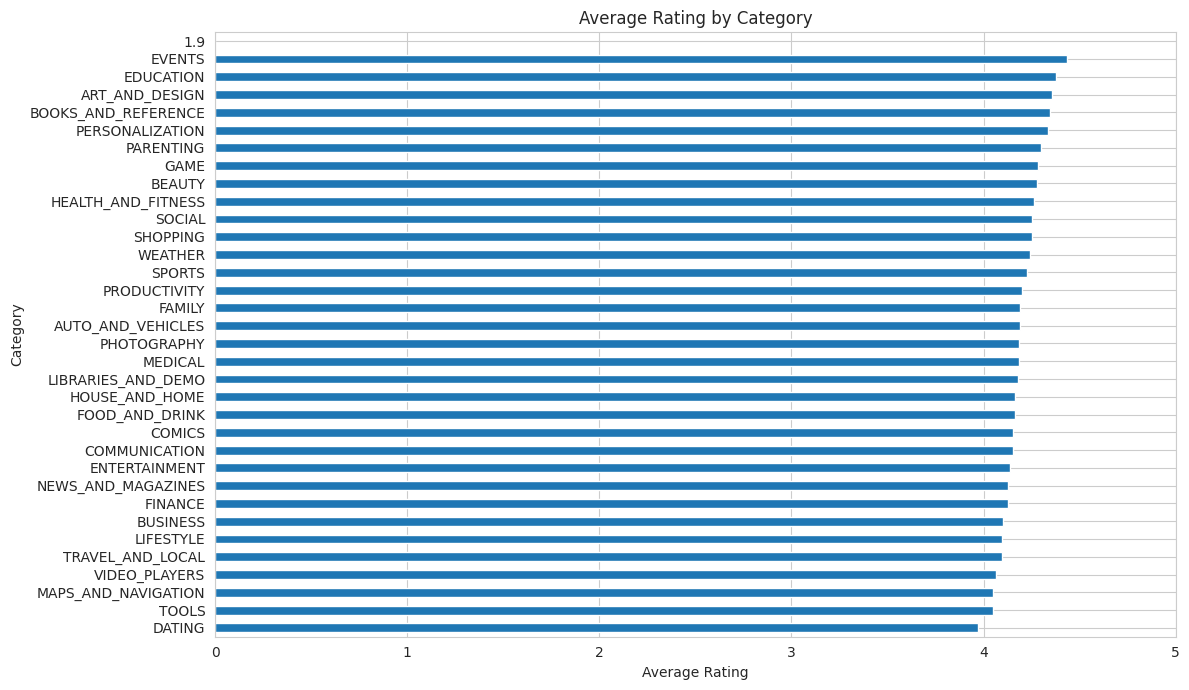

In [17]:
category_rating = (apps.groupby("Category")["Rating"].mean().sort_values(ascending=False))
plt.figure(figsize=(12, 7))
category_rating.sort_values().plot(kind="barh")
plt.title("Average Rating by Category")
plt.xlabel("Average Rating")
plt.ylabel("Category")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

### App Installation Analysis

The number of installs provides an indication of app reach.

We identify the apps with the highest recorded installation counts.
Install counts are approximate and are not exact numbers of active users.

In [18]:
top_installed = (apps.dropna(subset=["Installs"]).sort_values("Installs", ascending=False).drop_duplicates(subset=["App"]).head(10))
display(top_installed[["App", "Category", "Installs", "Rating"]])

,App,Category,Installs,Rating
3454,Google Drive,PRODUCTIVITY,1.000000e+09,4.4
865,Google Play Games,ENTERTAINMENT,1.000000e+09,4.3
2544,Facebook,SOCIAL,1.000000e+09,4.1
2545,Instagram,SOCIAL,1.000000e+09,4.5
464,Hangouts,COMMUNICATION,1.000000e+09,4.0
3223,Maps - Navigate & Explore,TRAVEL_AND_LOCAL,1.000000e+09,4.3
3816,Google News,NEWS_AND_MAGAZINES,1.000000e+09,3.9
3896,Subway Surfers,GAME,1.000000e+09,4.5
3687,Google Play Movies & TV,VIDEO_PLAYERS,1.000000e+09,3.7
3234,Google,TOOLS,1.000000e+09,4.4


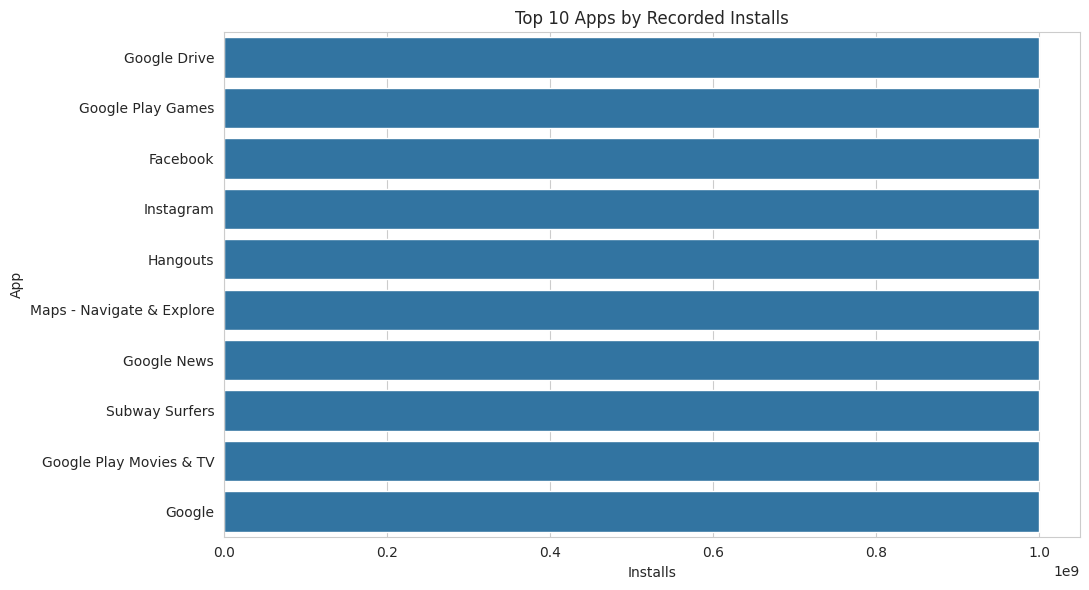

In [19]:
plt.figure(figsize=(11, 6))
sns.barplot(data=top_installed,x="Installs",y="App")
plt.title("Top 10 Apps by Recorded Installs")
plt.xlabel("Installs")
plt.ylabel("App")
plt.tight_layout()
plt.show()

###  Free vs. Paid Apps

We compare free and paid applications to understand which type
is more common and how their ratings differ.

We use the `Type` column to identify free and paid apps.

Type
Free    9591
Paid     765
0          1
Name: count, dtype: Int64


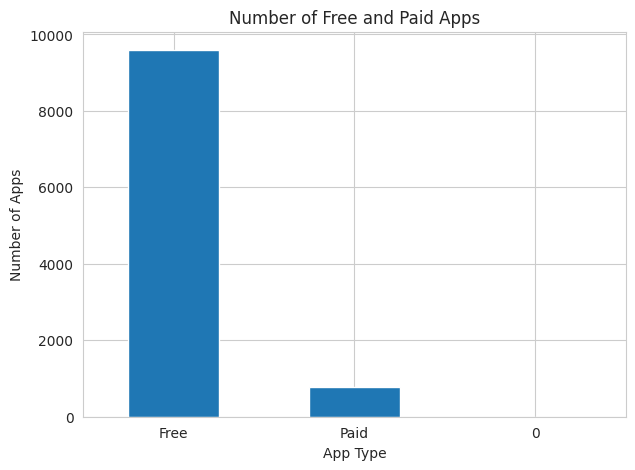

In [20]:
type_counts = apps["Type"].value_counts()
print(type_counts)
plt.figure(figsize=(7, 5))
type_counts.plot(kind="bar")
plt.title("Number of Free and Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Number of Apps")
plt.xticks(rotation=0)
plt.show()

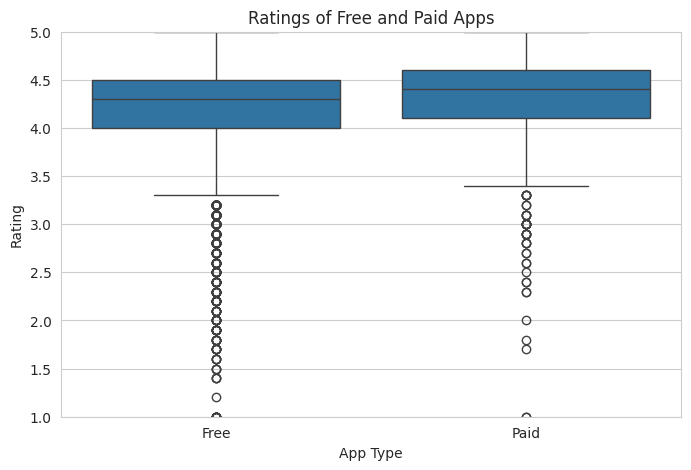

In [21]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=apps[apps["Type"].isin(["Free", "Paid"])],x="Type",y="Rating")
plt.title("Ratings of Free and Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Rating")
plt.ylim(1, 5)
plt.show()

###  Price Analysis

We examine the prices of paid applications.

Free applications have a price of zero, so they are excluded from
the paid-app price distribution.

Number of paid apps: 765
Average paid app price: 13.955555555555556
Median paid app price: 2.99


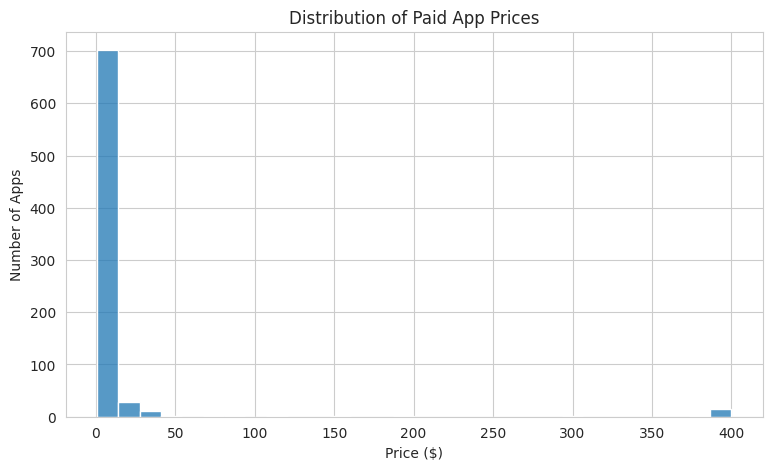

In [22]:
paid_apps = apps[(apps["Type"] == "Paid") &(apps["Price"] > 0)].copy()
print("Number of paid apps:", len(paid_apps))
print("Average paid app price:", paid_apps["Price"].mean())
print("Median paid app price:", paid_apps["Price"].median())
plt.figure(figsize=(9, 5))
sns.histplot(data=paid_apps,x="Price",bins=30)
plt.title("Distribution of Paid App Prices")
plt.xlabel("Price ($)")
plt.ylabel("Number of Apps")
plt.show()

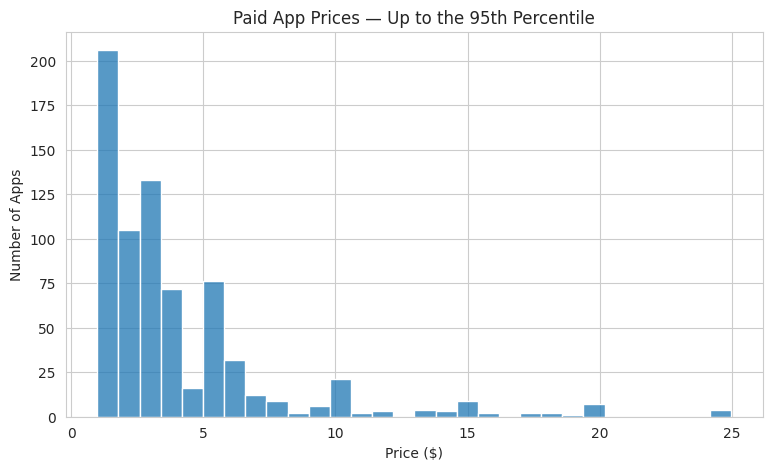

In [23]:
if not paid_apps.empty:
    price_limit = paid_apps["Price"].quantile(0.95)
    common_prices = paid_apps[paid_apps["Price"] <= price_limit]
    plt.figure(figsize=(9, 5))
    sns.histplot(data=common_prices, x="Price", bins=30)
    plt.title("Paid App Prices — Up to the 95th Percentile")
    plt.xlabel("Price ($)")
    plt.ylabel("Number of Apps")
    plt.show()

###  Content Rating Analysis

The content rating indicates the intended audience for an app.

We count the applications within each content rating group.

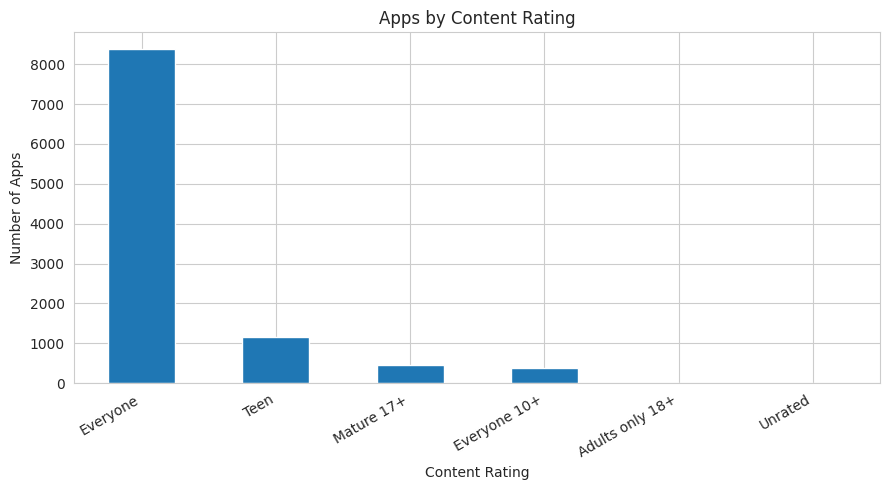

In [24]:
content_counts = apps["Content Rating"].value_counts()
plt.figure(figsize=(9, 5))
content_counts.plot(kind="bar")
plt.title("Apps by Content Rating")
plt.xlabel("Content Rating")
plt.ylabel("Number of Apps")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

###  Relationship Between Installs, Reviews, and Ratings

We examine whether apps with more reviews or installs tend to have
different ratings.

Install and review counts can span several orders of magnitude.
A logarithmic scale helps visualize their distributions more clearly.

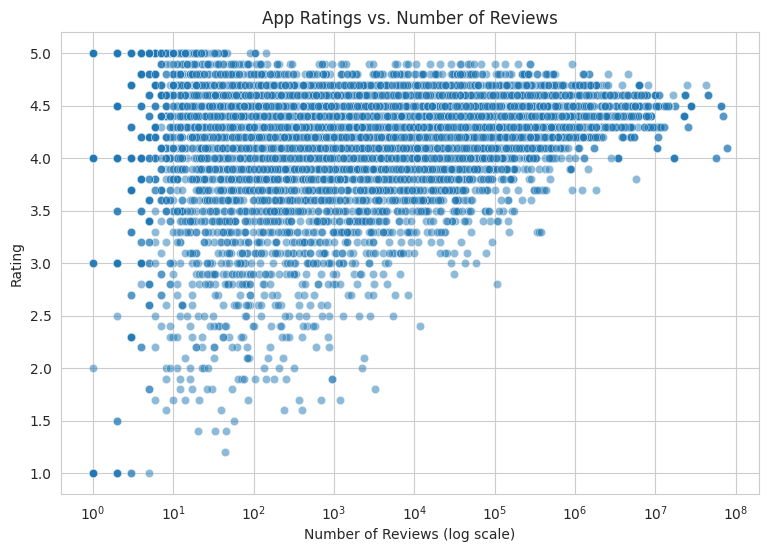

In [25]:
analysis_df = apps.dropna(subset=["Installs", "Reviews", "Rating"]).copy()
analysis_df = analysis_df[(analysis_df["Installs"] > 0) &(analysis_df["Reviews"] > 0)]
plt.figure(figsize=(9, 6))
sns.scatterplot(data=analysis_df,x="Reviews",y="Rating",alpha=0.5)
plt.xscale("log")
plt.title("App Ratings vs. Number of Reviews")
plt.xlabel("Number of Reviews (log scale)")
plt.ylabel("Rating")
plt.show()

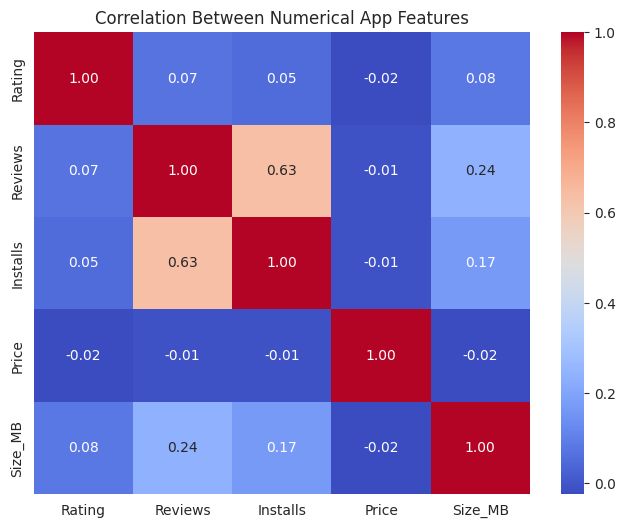

In [26]:
correlation_data = apps[["Rating", "Reviews", "Installs", "Price", "Size_MB"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_data,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Between Numerical App Features")
plt.show()

##  User Review Sentiment Analysis

The user reviews dataset includes translated review text and
sentiment labels.

The sentiment categories are generally:
- Positive
- Negative
- Neutral

We first examine the distribution of the available sentiment labels.

Sentiment counts:
Sentiment
Positive    19015
Negative     6321
Neutral      4356
Name: count, dtype: int64


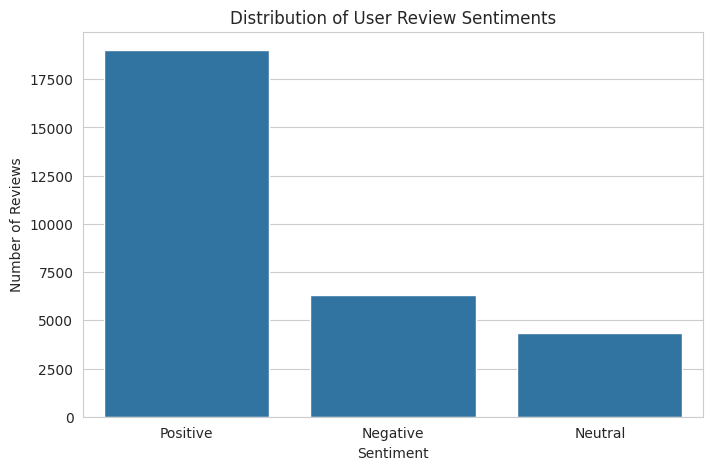

In [27]:
print("Sentiment counts:")
print(reviews["Sentiment"].value_counts(dropna=False))
plt.figure(figsize=(8, 5))
sns.countplot(data=reviews,x="Sentiment",order=reviews["Sentiment"].value_counts().index)
plt.title("Distribution of User Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

###  Sentiment Polarity

Sentiment polarity measures how positive or negative a review is.

In this dataset, polarity values generally range from -1 to +1:
- Negative values indicate negative sentiment.
- Values near zero indicate neutral or weak sentiment.
- Positive values indicate positive sentiment.

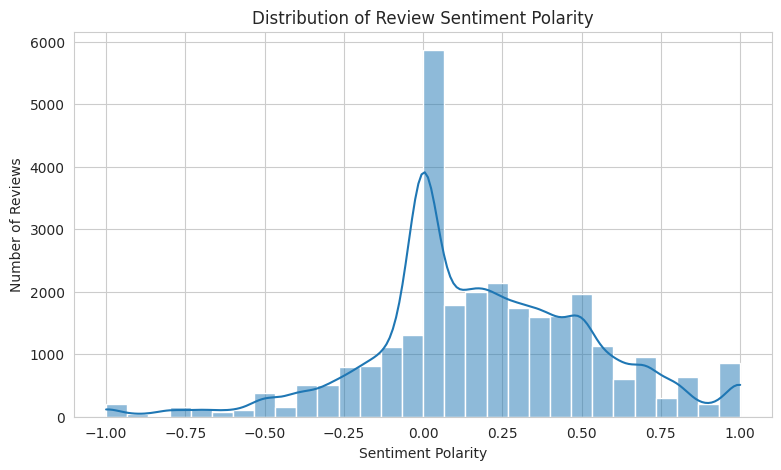

In [28]:
reviews["Sentiment_Polarity"] = pd.to_numeric(reviews["Sentiment_Polarity"],errors="coerce")
plt.figure(figsize=(9, 5))
sns.histplot(data=reviews,x="Sentiment_Polarity",bins=30,kde=True)
plt.title("Distribution of Review Sentiment Polarity")
plt.xlabel("Sentiment Polarity")
plt.ylabel("Number of Reviews")
plt.show()

###  Sentiment by Application

We compare average sentiment polarity across applications.

Only apps with a sufficient number of reviews are included to reduce
the influence of apps represented by just one or two reviews.

In [29]:
review_summary = (reviews.groupby("App").agg
    (
        Review_Count=("Translated_Review", "count"),
        Average_Polarity=("Sentiment_Polarity", "mean")
    ).reset_index()
)
review_summary = review_summary[review_summary["Review_Count"] >= 10]
top_reviewed = review_summary.sort_values("Review_Count",ascending=False).head(15)
display(top_reviewed)

,App,Review_Count,Average_Polarity
571,Facebook,130,-0.005909
536,Episode - Choose Your Story,124,0.082734
114,Angry Birds Classic,107,-0.023874
583,Family Locator - GPS Tracker,105,0.341109
754,Google Photos,101,0.187021
24,8fit Workouts & Meal Planner,100,0.297167
327,Calorie Counter - Macros,100,0.247519
378,ColorNote Notepad Notes,99,0.286861
328,Calorie Counter - MyFitnessPal,99,0.232979
209,Be A Legend: Soccer,98,-0.099251


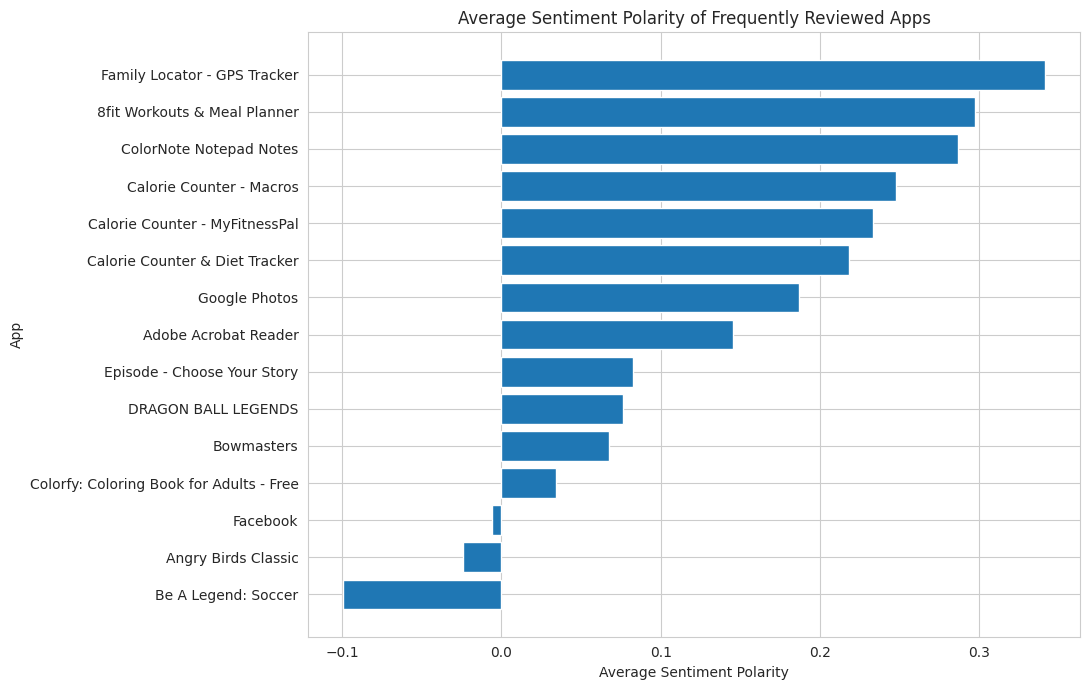

In [30]:
if not top_reviewed.empty:
    sentiment_plot = top_reviewed.sort_values("Average_Polarity")
    plt.figure(figsize=(11, 7))
    plt.barh(sentiment_plot["App"],sentiment_plot["Average_Polarity"])
    plt.title("Average Sentiment Polarity of Frequently Reviewed Apps")
    plt.xlabel("Average Sentiment Polarity")
    plt.ylabel("App")
    plt.tight_layout()
    plt.show()

## Combined App and Sentiment Analysis

We summarize review sentiment by app and merge the summary with
the app dataset.

Instead of merging every review row, we aggregate reviews first.
This avoids creating repeated app rows in the combined dataset.

In [31]:
sentiment_by_app = (
    reviews.groupby("App").agg
    (
        Review_Count=("Translated_Review", "count"),
        Average_Polarity=("Sentiment_Polarity", "mean"),
        Positive_Reviews=("Sentiment",lambda x: (x == "Positive").sum()),
        Negative_Reviews=("Sentiment",lambda x: (x == "Negative").sum()),
        Neutral_Reviews=("Sentiment",lambda x: (x == "Neutral").sum())
    ).reset_index()
)

combined_df = apps.merge(sentiment_by_app,on="App",how="left")
display(combined_df.head())
print("Combined dataset shape:", combined_df.shape)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB,Review_Count,Average_Polarity,Positive_Reviews,Negative_Reviews,Neutral_Reviews
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159.0,19M,10000.0,Free,0.0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up,19.0,NaN,NaN,NaN,NaN,NaN
1,Coloring book moana,ART_AND_DESIGN,3.9,967.0,14M,500000.0,Free,0.0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up,14.0,20.0,0.117917,11.0,7.0,2.0
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510.0,8.7M,5000000.0,Free,0.0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up,8.7,NaN,NaN,NaN,NaN,NaN
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644.0,25M,50000000.0,Free,0.0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up,25.0,NaN,NaN,NaN,NaN,NaN
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967.0,2.8M,100000.0,Free,0.0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up,2.8,NaN,NaN,NaN,NaN,NaN


Combined dataset shape: (10358, 19)


##  Export Results

We save the cleaned app dataset, cleaned review dataset, and
aggregated sentiment summary as CSV files.

These files can be reused for further analysis without repeating
the initial cleaning steps.

In [32]:
apps.to_csv("googleplaystore_cleaned.csv", index=False)
reviews.to_csv("googleplaystore_reviews_cleaned.csv", index=False)
sentiment_by_app.to_csv("googleplaystore_sentiment_summary.csv", index=False)
print("Export completed successfully!")

Export completed successfully!


In [33]:
from google.colab import files
files.download("googleplaystore_cleaned.csv")
files.download("googleplaystore_reviews_cleaned.csv")
files.download("googleplaystore_sentiment_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##  Conclusion

In this project, we analyzed Google Play Store applications and
user reviews using Python data analysis and visualization libraries.

The apps dataset was inspected and cleaned, including the conversion
of ratings, installation counts, reviews, prices, and app sizes into
appropriate formats.

Exploratory data analysis was used to study app categories, rating
distributions, installation counts, free and paid applications,
content ratings, and relationships between numerical features.

The user reviews dataset was analyzed to understand sentiment
distribution, sentiment polarity, and differences in expressed
opinions across applications.

The analysis provides insights into the characteristics of apps
available in the Google Play Store and the opinions expressed in
the available user reviews.

The findings are descriptive and do not establish that any single
factor causes an app to become popular or receive higher ratings.